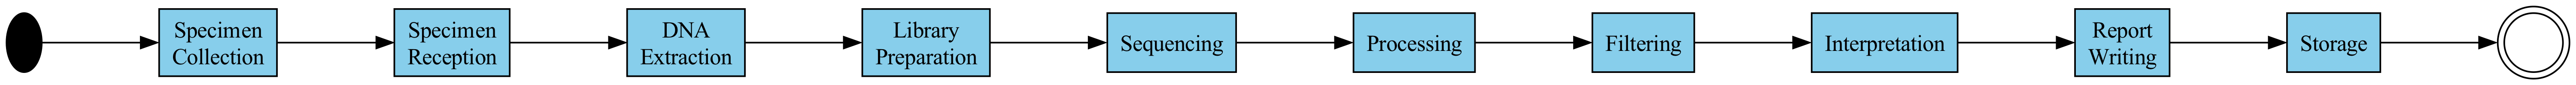

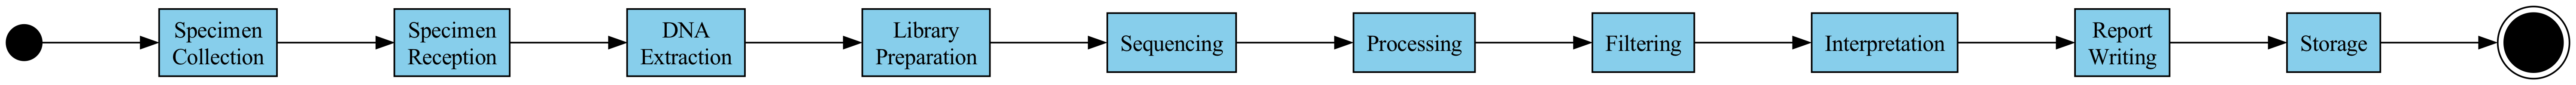

In [1]:
# Copyright 2026 Dylan. SPDX-License-Identifier: Apache-2.0
# Required imports
import graphviz
from IPython.display import Image
from IPython.display import display as show_output

# Define the steps
steps = [
    "Specimen Collection",
    "Specimen Reception",
    "DNA Extraction",
    "Library Preparation",
    "Sequencing",
    "Processing",
    "Filtering",
    "Interpretation",
    "Report Writing",
    "Storage",
]


# Function to adjust diagram attributes for better visualization
def adjust_diagram_attributes(dot_graph: graphviz.Digraph) -> graphviz.Digraph:
    """Set graph attributes for the workflow diagram."""
    dot_graph.attr(size="20,5")
    dot_graph.attr(dpi="300")
    dot_graph.attr(ranksep="1")
    dot_graph.attr(nodesep="0.75")
    return dot_graph


# Function to adjust node labels for multiline display
def set_multiline_labels(dot_graph: graphviz.Digraph) -> graphviz.Digraph:
    """Format node labels over multiple lines."""
    for node in dot_graph.body:
        if "label" in node:
            parts = node.split('label="')
            if len(parts) > 1:
                label_content = parts[1].split('"')[0]
                new_label_content = label_content.replace(" ", "\\n")
                dot_graph.body[dot_graph.body.index(node)] = node.replace(
                    label_content,
                    new_label_content,
                )
    return dot_graph


# Function to double the text size and vertical height of the boxes
def double_text_and_box_size(dot_graph: graphviz.Digraph) -> graphviz.Digraph:
    """Enlarge text and boxes in the workflow diagram."""
    dot_graph.attr(fontsize="64", height="2")
    return dot_graph


# Function to generate BPMN diagram
def generate_bpmn(steps: list[str]) -> graphviz.Digraph:
    """Build a BPMN-style graph from the workflow steps."""
    dot = graphviz.Digraph(
        comment="BPMN Diagram",
        format="png",
        node_attr={"style": "filled", "shape": "box", "fillcolor": "skyblue"},
    )
    dot.attr(rankdir="LR")

    # Add start event
    dot.node("start", label="", shape="ellipse", fillcolor="black", width="0.3")

    # Add steps
    for i, step in enumerate(steps):
        dot.node(str(i), step)
        if i == 0:
            dot.edge("start", str(i))
        else:
            dot.edge(str(i - 1), str(i))

    # Add end event
    dot.node("end", label="", shape="doublecircle", fillcolor="white", width="0.5")
    dot.edge(str(len(steps) - 1), "end")

    return dot


# Function to generate UML Activity Diagram
def generate_uml_activity(steps: list[str]) -> graphviz.Digraph:
    """Build a UML activity graph from the workflow steps."""
    dot = graphviz.Digraph(
        comment="UML Activity Diagram",
        format="png",
        node_attr={"style": "filled", "shape": "box", "fillcolor": "skyblue"},
    )
    dot.attr(rankdir="LR")

    # Add initial node
    dot.node("initial", label="", shape="circle", fillcolor="black", width="0.3")

    # Add steps
    for i, step in enumerate(steps):
        dot.node(str(i), step)
        if i == 0:
            dot.edge("initial", str(i))
        else:
            dot.edge(str(i - 1), str(i))

    # Add final node
    dot.node("final", label="", shape="doublecircle", fillcolor="black", width="0.5")
    dot.edge(str(len(steps) - 1), "final")

    return dot


# Generate and adjust diagrams
bpmn_diagram = generate_bpmn(steps)
uml_diagram = generate_uml_activity(steps)
bpmn_diagram = adjust_diagram_attributes(bpmn_diagram)
uml_diagram = adjust_diagram_attributes(uml_diagram)
bpmn_diagram = set_multiline_labels(bpmn_diagram)
uml_diagram = set_multiline_labels(uml_diagram)
bpmn_diagram = double_text_and_box_size(bpmn_diagram)
uml_diagram = double_text_and_box_size(uml_diagram)

# Render and display diagrams
bpmn_diagram.render(filename="bpmn_diagram_final", format="png", cleanup=True)
uml_diagram.render(filename="uml_diagram_final", format="png", cleanup=True)
show_output(Image(filename="bpmn_diagram_final.png"))
show_output(Image(filename="uml_diagram_final.png"))